# Лабораторная работа №4. Байесовская сеть
**Цель:** построить сеть зависимостей и посмотреть, как новая информация меняет вероятности.

## 1. Данные
Используем белые вина **Wine Quality**: один объект — образец вина с измерениями и оценкой дегустаторов. Берём четыре переменные:

| Переменная | Смысл | Состояния |
|---|---|---|
| Alcohol | Содержание алкоголя, % об. | низкое / среднее / высокое |
| Sugar | Остаточный сахар, г/л | низкий / средний / высокий |
| Density | Плотность, г/см³ | низкая / средняя / высокая |
| Quality | Оценка качества от 0 до 10 | обычное (< 7) / высокое (≥ 7) |

Остальные 8 столбцов в сеть не включаем. Сахар и алкоголь связаны с брожением, плотностью и вкусом.

Источник: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), Cortez et al. (2009), [DOI](https://doi.org/10.24432/C56S3T), лицензия CC BY 4.0. Исходный CSV приложен; интернет для запуска не нужен.

In [1]:
from pathlib import Path
from itertools import product
from graphlib import TopologicalSorter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11})
raw = pd.read_csv(Path('data') / 'winequality-white.csv', sep=';')
print(f'Строк: {len(raw)}, столбцов: {raw.shape[1]}')
print(f'Пропусков: {raw.isna().sum().sum()}, полных повторов: {raw.duplicated().sum()}')
display(raw[['alcohol', 'residual sugar', 'density', 'quality']].describe().round(3))

Строк: 4898, столбцов: 12
Пропусков: 0, полных повторов: 937


,alcohol,residual sugar,density,quality
count,4898.000,4898.000,4898.000,4898.000
mean,10.514,6.391,0.994,5.878
std,1.231,5.072,0.003,0.886
min,8.000,0.600,0.987,3.000
25%,9.500,1.700,0.992,5.000
50%,10.400,5.200,0.994,6.000
75%,11.400,9.900,0.996,6.000
max,14.200,65.800,1.039,9.000


## 2. Подготовка
Удаляем только полные повторы по всем 12 столбцам: идентификаторов нет, поэтому считаем их возможными дублями. Это меняет частоты; выводы относятся к оставшимся уникальным строкам.

Непрерывные признаки делим по тертилям (квантили 1/3 и 2/3). Так группы получаются примерно равными, а таблицы вероятностей — небольшими. Это относительные уровни внутри выборки, а не нормы для вина. Редкие оценки 8–9 объединяем с 7.

Здесь исследуем распределение выбранных данных, а не качество прогноза на новых объектах. Поэтому оцениваем границы и вероятности на всей очищенной выборке; тестовых метрик не заявляем.

In [2]:
clean = raw.drop_duplicates().dropna().copy()
levels = ['низкий', 'средний', 'высокий']
states = {name: levels.copy() for name in ['Alcohol', 'Sugar', 'Density']}
states['Quality'] = ['обычное', 'высокое']
data = pd.DataFrame(index=clean.index)
bounds = []
for name, col in [('Alcohol', 'alcohol'), ('Sugar', 'residual sugar'), ('Density', 'density')]:
    q1, q2 = clean[col].quantile([1/3, 2/3])
    data[name] = pd.cut(clean[col], [-np.inf, q1, q2, np.inf], labels=levels).astype(str)
    bounds.append({'признак': name, 'граница 1': q1, 'граница 2': q2})
data['Quality'] = np.where(clean['quality'] >= 7, 'высокое', 'обычное')
print(f'После очистки: {len(data)} строк; интервалы: x ≤ q1, q1 < x ≤ q2, x > q2.')
display(pd.DataFrame(bounds).set_index('признак').round(6))
display(pd.DataFrame({v: data[v].value_counts() for v in states}).fillna(0).astype(int))
print('Возможных совместных состояний:', np.prod([len(s) for s in states.values()]))

После очистки: 3961 строк; интервалы: x ≤ q1, q1 < x ≤ q2, x > q2.


,граница 1,граница 2
признак,,
Alcohol,9.8000,11.066667
Sugar,2.1000,7.400000
Density,0.9922,0.995000


,Alcohol,Sugar,Density,Quality
высокий,1321,1317,1311,0
высокое,0,0,0,825
низкий,1327,1320,1322,0
обычное,0,0,0,3136
средний,1313,1324,1328,0


Возможных совместных состояний: 54


## 3. Вопросы до построения сети
1. Как меняется вероятность высокого качества, если алкоголь высокий?
2. Какова вероятность высокого качества при высоком алкоголе и низком сахаре?
3. Как низкая плотность меняет вероятность высокого алкоголя?

## 4. Структура сети
Выбираем рёбра вручную:

| Ребро | Обоснование и направление |
|---|---|
| Alcohol → Sugar | Брожение связывает образование спирта и расход сахара. Условно описываем сахар через алкоголь; обратное направление тоже допустимо. |
| Alcohol → Density | Содержание спирта связано с плотностью смеси; задаём направление от состава к свойству. |
| Sugar → Density | Растворённый сахар связан с плотностью; направление также от состава к свойству. |
| Alcohol → Quality | Алкоголь связан с восприятием вкуса; состав измерен до оценки. |
| Sugar → Quality | Сладость может влиять на оценку; направление от состава к оценке. |

Это гипотезы о зависимостях, а не вывод из корреляции. Неучтённые технология и состав могут объяснять часть связей. Предполагаем, что при известных Alcohol и Sugar плотность не даёт дополнительной информации о качестве.

Факторизация: **P(A, S, D, Q) = P(A) · P(S|A) · P(D|A,S) · P(Q|A,S)**.

Топологический порядок: Alcohol → Sugar → Density → Quality


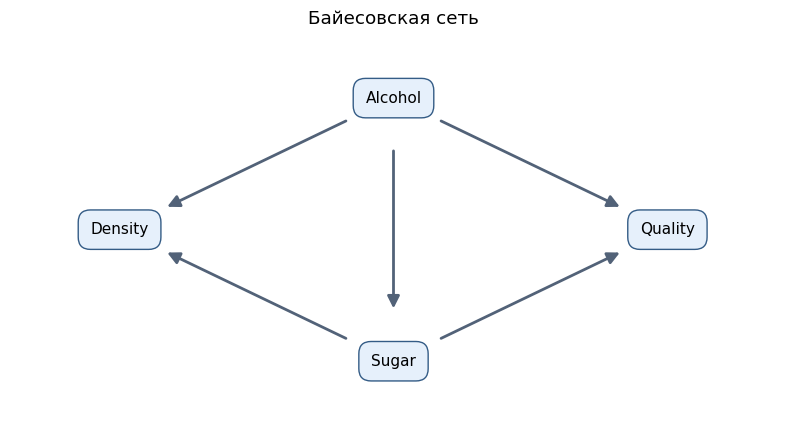

In [3]:
parents = {'Alcohol': [], 'Sugar': ['Alcohol'],
           'Density': ['Alcohol', 'Sugar'], 'Quality': ['Alcohol', 'Sugar']}
order = list(TopologicalSorter(parents).static_order())  # ошибка, если есть цикл
print('Топологический порядок:', ' → '.join(order))
positions = {'Alcohol': (0, 1), 'Sugar': (0, -1), 'Density': (-2, 0), 'Quality': (2, 0)}
fig, ax = plt.subplots(figsize=(8, 4.5))
for child, ps in parents.items():
    for parent in ps:
        ax.annotate('', xy=positions[child], xytext=positions[parent],
                    arrowprops=dict(arrowstyle='-|>', color='#526278', lw=2,
                                    shrinkA=38, shrinkB=38, mutation_scale=18))
for node, (x, y) in positions.items():
    ax.text(x, y, node, ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.8', fc='#e6f0fb', ec='#345c86'))
ax.set(xlim=(-2.8, 2.8), ylim=(-1.5, 1.5), title='Байесовская сеть')
ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Условные вероятности
Используем частоты со сглаживанием Лапласа: **P(x|pa) = (N(x,pa) + 1) / (N(pa) + k)**, где k — число состояний узла. Оно убирает нулевые вероятности, но не заменяет реальные наблюдения.

Для небольшой сети реализуем таблицы и точный вывод самостоятельно: всего 54 совместных состояния.

In [4]:
def fit_cpds(frame, graph, alpha=1.0):
    list(TopologicalSorter(graph).static_order())
    tables = {}
    for node, ps in graph.items():
        rows = []
        for values in product(*(states[p] for p in ps)):
            subset = frame
            for p, value in zip(ps, values):
                subset = subset.loc[subset[p] == value]
            counts = subset[node].value_counts().reindex(states[node], fill_value=0)
            probs = (counts + alpha) / (len(subset) + alpha * len(states[node]))
            rows.append([*values, len(subset), *probs])
        tables[node] = pd.DataFrame(rows, columns=[*ps, 'n', *states[node]])
    return tables

cpds = fit_cpds(data, parents)
for node in ['Density', 'Quality']:
    print(f'P({node} | Alcohol, Sugar)')
    display(cpds[node].round(4))
support = pd.DataFrame([
    {'узел': v, 'строк CPT': len(t), 'min n родителей': t['n'].min(),
     'групп с n < 30': int((t['n'] < 30).sum()),
     'свободных параметров': len(t) * (len(states[v]) - 1)}
    for v, t in cpds.items()])
display(support)
print('Всего свободных параметров:', support['свободных параметров'].sum())

P(Density | Alcohol, Sugar)


,Alcohol,Sugar,n,низкий,средний,высокий
0,низкий,низкий,237,0.0500,0.8458,0.1042
1,низкий,средний,306,0.0032,0.5340,0.4628
2,низкий,высокий,784,0.0013,0.0152,0.9835
3,средний,низкий,532,0.3963,0.5776,0.0262
4,средний,средний,416,0.0979,0.7470,0.1551
5,средний,высокий,365,0.0027,0.2554,0.7418
6,высокий,низкий,551,0.9549,0.0433,0.0018
7,высокий,средний,602,0.8215,0.1752,0.0033
8,высокий,высокий,168,0.2164,0.6491,0.1345


P(Quality | Alcohol, Sugar)


,Alcohol,Sugar,n,обычное,высокое
0,низкий,низкий,237,0.9498,0.0502
1,низкий,средний,306,0.9643,0.0357
2,низкий,высокий,784,0.9402,0.0598
3,средний,низкий,532,0.8315,0.1685
4,средний,средний,416,0.8254,0.1746
5,средний,высокий,365,0.8747,0.1253
6,высокий,низкий,551,0.6691,0.3309
7,высокий,средний,602,0.4967,0.5033
8,высокий,высокий,168,0.6000,0.4000


,узел,строк CPT,min n родителей,групп с n < 30,свободных параметров
0,Alcohol,1,3961,0,2
1,Sugar,3,1313,0,6
2,Density,9,168,0,18
3,Quality,9,168,0,9


Всего свободных параметров: 35


In [5]:
# Сравним условные вероятности качества с частотами в тех же группах.
empirical = (data.assign(high=data['Quality'].eq('высокое'))
             .groupby(['Alcohol', 'Sugar'])['high'].agg(['mean', 'size']).reset_index())
comparison = cpds['Quality'].merge(empirical, on=['Alcohol', 'Sugar'])
comparison = comparison[['Alcohol', 'Sugar', 'size', 'mean', 'высокое']]
comparison.columns = ['Alcohol', 'Sugar', 'n', 'частота высокого', 'CPT высокого']
comparison['разница'] = comparison['CPT высокого'] - comparison['частота высокого']
display(comparison.round(4))
print('Максимальная поправка сглаживания:', round(comparison['разница'].abs().max(), 4))

,Alcohol,Sugar,n,частота высокого,CPT высокого,разница
0,низкий,низкий,237,0.0464,0.0502,0.0038
1,низкий,средний,306,0.0327,0.0357,0.0030
2,низкий,высокий,784,0.0587,0.0598,0.0011
3,средний,низкий,532,0.1673,0.1685,0.0012
4,средний,средний,416,0.1731,0.1746,0.0016
5,средний,высокий,365,0.1233,0.1253,0.0021
6,высокий,низкий,551,0.3303,0.3309,0.0006
7,высокий,средний,602,0.5033,0.5033,-0.0000
8,высокий,высокий,168,0.3988,0.4000,0.0012


Максимальная поправка сглаживания: 0.0038


В каждой группе родителей есть минимум **168 наблюдений**; всего оцениваем 35 свободных параметров по 3961 строке. Пустых и малых групп (n < 30) нет, но отдельные исходы внутри них могут быть редкими.

При высоком алкоголе и низком сахаре низкая плотность имеет вероятность **95,5%**; при низком алкоголе и высоком сахаре высокая плотность — **98,4%**. Это согласуется с выбранными зависимостями состава и плотности.

Неожиданно при высоком алкоголе средний сахар даёт больше высоких оценок, чем низкий: **50,3% против 33,1%**. Та же разница есть в исходных частотах, то есть она не создана сглаживанием. Возможное объяснение — баланс вкуса или неучтённый стиль вина; по этим данным различить причины нельзя.

Число наблюдений проверяем именно для сочетаний родителей, а не только для отдельных категорий. Чем меньше n, тем менее надёжна строка CPT. Совпадение CPT и частот здесь проверяет оценку параметров, но не доказывает качество всей модели.

In [6]:
def make_joint(tables, graph):
    nodes = list(graph)
    rows = []
    for values in product(*(states[v] for v in nodes)):
        assignment = dict(zip(nodes, values))
        probability = 1.0
        for node, ps in graph.items():
            row = tables[node]
            for p in ps:
                row = row.loc[row[p] == assignment[p]]
            probability *= float(row.iloc[0][assignment[node]])
        rows.append([*values, probability])
    return pd.DataFrame(rows, columns=[*nodes, 'p'])

joint = make_joint(cpds, parents)

def query(target, evidence=None, distribution=None):
    evidence = evidence or {}
    if target in evidence:
        raise ValueError('Целевая переменная не должна входить в evidence')
    part = joint if distribution is None else distribution
    for node, value in evidence.items():
        if value not in states[node]:
            raise ValueError(f'Неизвестное состояние {node}: {value}')
        part = part.loc[part[node] == value]
    mass = part['p'].sum()
    if mass <= 0:
        raise ValueError('Evidence имеет нулевую вероятность')
    return part.groupby(target)['p'].sum().reindex(states[target], fill_value=0) / mass

requests = [
    ('1. Высокое качество при высоком алкоголе', 'Quality', 'высокое', {'Alcohol': 'высокий'}),
    ('2. Высокое качество: алкоголь высокий, сахар низкий', 'Quality', 'высокое',
     {'Alcohol': 'высокий', 'Sugar': 'низкий'}),
    ('3. Высокий алкоголь при низкой плотности', 'Alcohol', 'высокий', {'Density': 'низкий'})]
rows = []
for question, target, state, evidence in requests:
    prior = query(target)[state]
    posterior = query(target, evidence)[state]
    mask = pd.Series(True, index=data.index)
    for v, s in evidence.items():
        mask &= data[v].eq(s)
    rows.append({'вопрос': question, 'до': prior, 'после': posterior,
                 'изменение, п.п.': 100 * (posterior - prior), 'n evidence': int(mask.sum()),
                 'частота в данных': data.loc[mask, target].eq(state).mean()})
answers = pd.DataFrame(rows).set_index('вопрос')
display(answers.round(4))

,до,после,"изменение, п.п.",n evidence,частота в данных
вопрос,,,,,
1. Высокое качество при высоком алкоголе,0.2096,0.4183,20.8642,1321,0.4179
"2. Высокое качество: алкоголь высокий, сахар низкий",0.2096,0.3309,12.1312,551,0.3303
3. Высокий алкоголь при низкой плотности,0.3335,0.7987,46.5206,1322,0.8018


## 6. Вероятностный вывод
В таблице «до» — вероятность без evidence, «после» — с указанными наблюдениями. Последний столбец даёт проверку по исходным частотам; несовпадение возможно из-за сглаживания и ограничений графа.

In [7]:
for label, row in answers.iterrows():
    direction = 'увеличилась' if row['после'] > row['до'] else 'уменьшилась'
    print(f"{label}: вероятность {direction} с {row['до']:.1%} до {row['после']:.1%}.")
print('Первые два запроса описывают связь состава с оценкой, а не эффект изменения рецепта.')
print('Третий — обратный вывод: по свойству смеси уточняем вероятный состав.')

1. Высокое качество при высоком алкоголе: вероятность увеличилась с 21.0% до 41.8%.
2. Высокое качество: алкоголь высокий, сахар низкий: вероятность увеличилась с 21.0% до 33.1%.
3. Высокий алкоголь при низкой плотности: вероятность увеличилась с 33.4% до 79.9%.
Первые два запроса описывают связь состава с оценкой, а не эффект изменения рецепта.
Третий — обратный вывод: по свойству смеси уточняем вероятный состав.


## 7. Последовательное добавление evidence
Следим за **Quality**: сначала ничего не известно, затем узнаём плотность, сахар и алкоголь. Используем вложенные наборы наблюдений, поэтому каждый шаг добавляет ровно один факт.

Quality,обычное,высокое
Нет данных,0.7904,0.2096
Плотность низкая,0.6365,0.3635
+ сахар низкий,0.7192,0.2808
+ алкоголь высокий,0.6691,0.3309


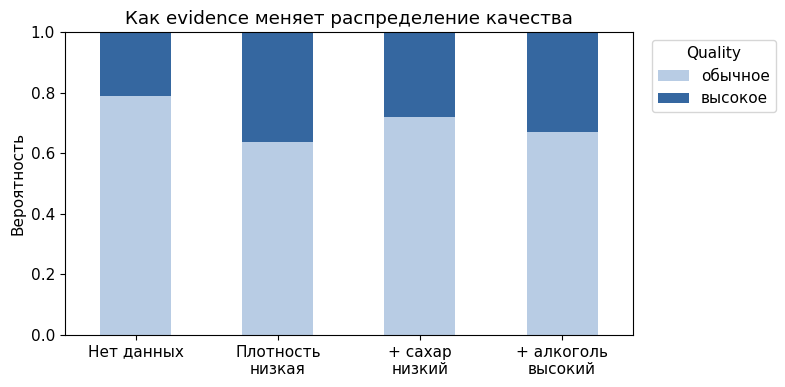

Плотность низкая: +15.38 п.п. к вероятности высокого качества
+ сахар низкий: -8.27 п.п. к вероятности высокого качества
+ алкоголь высокий: +5.02 п.п. к вероятности высокого качества
После фиксации алкоголя и сахара вклад плотности: 0.0


In [8]:
evidence_steps = [{}, {'Density': 'низкий'},
    {'Density': 'низкий', 'Sugar': 'низкий'},
    {'Density': 'низкий', 'Sugar': 'низкий', 'Alcohol': 'высокий'}]
step_labels = ['Нет данных', 'Плотность низкая', '+ сахар низкий', '+ алкоголь высокий']
evolution = pd.DataFrame([query('Quality', e) for e in evidence_steps], index=step_labels)
display(evolution.round(4))
ax = evolution.plot.bar(stacked=True, color=['#b8cce4', '#3567a0'], rot=0)
ax.set_xticklabels(['Нет данных', 'Плотность\nнизкая', '+ сахар\nнизкий', '+ алкоголь\nвысокий'], rotation=0)
ax.set(xlabel='', ylabel='Вероятность', ylim=(0, 1), title='Как evidence меняет распределение качества')
ax.legend(title='Quality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
for i in range(1, len(evolution)):
    delta = 100 * (evolution.iloc[i]['высокое'] - evolution.iloc[i-1]['высокое'])
    print(f'{step_labels[i]}: {delta:+.2f} п.п. к вероятности высокого качества')
print('После фиксации алкоголя и сахара вклад плотности:',
      round(query('Quality', evidence_steps[-1])['высокое'] -
            query('Quality', {'Alcohol': 'высокий', 'Sugar': 'низкий'})['высокое'], 12))

Плотность даёт косвенную информацию об алкоголе и сахаре. Известный сахар уточняет вывод об алкоголе через общую дочернюю вершину Density. Затем известный алкоголь фиксирует второго родителя Quality.

Когда Alcohol и Sugar уже заданы, плотность больше не меняет распределение Quality: это условная независимость, заложенная в граф. Новая информация не обязана каждый раз повышать вероятность высокого качества: здесь низкая плотность повышает её на 15,38 п.п., низкий сахар снижает на 8,27 п.п., высокий алкоголь снова повышает на 5,02 п.п. Снижение при добавлении сахара согласуется с CPT: для высокого алкоголя низкий сахар связан с меньшей долей высоких оценок, чем средний.

## 8. Удаление ребра
Удалим **Alcohol → Quality**, заново оценим CPT на тех же данных и повторим второй запрос. Границы категорий и сглаживание сохраняем.

In [9]:
reduced_parents = {v: ps.copy() for v, ps in parents.items()}
reduced_parents['Quality'].remove('Alcohol')
reduced_cpds = fit_cpds(data, reduced_parents)
reduced_joint = make_joint(reduced_cpds, reduced_parents)
evidence = {'Alcohol': 'высокий', 'Sugar': 'низкий'}
structure_result = pd.DataFrame({
    'исходная сеть': query('Quality', evidence),
    'без Alcohol → Quality': query('Quality', evidence, reduced_joint)})
display(structure_result.round(4))
structure_delta = 100 * (structure_result.loc['высокое'].iloc[1] - structure_result.loc['высокое'].iloc[0])
print(f'Изменение вероятности высокого качества: {structure_delta:+.2f} п.п.')

,исходная сеть,без Alcohol → Quality
Quality,,
обычное,0.6691,0.7859
высокое,0.3309,0.2141


Изменение вероятности высокого качества: -11.69 п.п.


После удаления ребра Quality зависит только от Sugar. Поэтому при известном сахаре сведения об алкоголе перестают влиять на оценку качества. CPT теперь усредняет вина с разным алкоголем, и ответ меняется.

Направление рёбер нельзя уверенно определить только по этим наблюдениям: разные DAG могут описывать одинаковые условные независимости. Нужны дополнительные знания или эксперимент.

## 9. Причинность
**Эта сеть не является доказанной причинной моделью.** Направления к плотности мотивированы составом смеси, но наблюдений недостаточно для оценки эффекта вмешательства. Технология производства и другие вещества не учтены. В частности, связь Alcohol → Sugar — способ факторизации, а не утверждение, что добавление спирта уменьшает сахар.

Запрос P(Quality | Alcohol) описывает наблюдаемую группу вин, а не результат принудительного изменения алкоголя.

## 10. Проверка реализации
Проверяем DAG, нормировку CPT и совместного распределения, ответы на запросы и условные независимости. Дополнительно сверяем полный перебор с прямой формулой для третьего запроса.

In [10]:
for graph, tables, distribution in [(parents, cpds, joint),
                                    (reduced_parents, reduced_cpds, reduced_joint)]:
    assert len(list(TopologicalSorter(graph).static_order())) == 4
    assert len(distribution) == 54
    assert np.isclose(distribution['p'].sum(), 1)
    assert (distribution['p'] > 0).all()
    for node, table in tables.items():
        assert np.allclose(table[states[node]].sum(axis=1), 1)
    for e in evidence_steps:
        assert np.isclose(query('Quality', e, distribution).sum(), 1)

assert np.allclose(query('Quality', evidence_steps[-1]), query('Quality', evidence))
assert np.allclose(query('Quality', evidence, reduced_joint),
                   query('Quality', {'Sugar': 'низкий'}, reduced_joint))

# Независимая проверка запроса P(A=высокий | D=низкий) по формуле Байеса.
weights = []
for a in states['Alcohol']:
    p_a = (data['Alcohol'].eq(a).sum() + 1) / (len(data) + 3)
    group = data.loc[data['Alcohol'].eq(a)]
    likelihood = 0.0
    for s in states['Sugar']:
        subgroup = group.loc[group['Sugar'].eq(s)]
        p_s_a = (len(subgroup) + 1) / (len(group) + 3)
        p_d_as = (subgroup['Density'].eq('низкий').sum() + 1) / (len(subgroup) + 3)
        likelihood += p_s_a * p_d_as
    weights.append(p_a * likelihood)
assert np.allclose(np.array(weights) / sum(weights), query('Alcohol', {'Density': 'низкий'}))
assert comparison['разница'].abs().max() < 0.02
print('Все проверки пройдены.')

Все проверки пройдены.


## 11. Итог

In [11]:
print(f"Высокое качество: без evidence {answers.iloc[0]['до']:.1%}, "
      f"при высоком алкоголе {answers.iloc[0]['после']:.1%}, "
      f"при высоком алкоголе и низком сахаре {answers.iloc[1]['после']:.1%}.")
print(f"Низкая плотность меняет вероятность высокого алкоголя "
      f"с {answers.iloc[2]['до']:.1%} до {answers.iloc[2]['после']:.1%}.")
print(f'Удаление Alcohol → Quality изменило ответ на {structure_delta:+.2f} п.п.')

Высокое качество: без evidence 21.0%, при высоком алкоголе 41.8%, при высоком алкоголе и низком сахаре 33.1%.
Низкая плотность меняет вероятность высокого алкоголя с 33.4% до 79.9%.
Удаление Alcohol → Quality изменило ответ на -11.69 п.п.


Наиболее интересны связь алкоголя с качеством и обратный вывод о составе по плотности. Evidence уточняет распределение, но его эффект зависит от уже известных переменных и структуры сети.

**Ограничения:** дискретизация теряет точные значения; полные повторы удалены по допущению; часть состава и технология не учтены; вероятности описывают эту выборку, а не все вина. Сглаживание и небольшой DAG упрощают реальные зависимости. Для проверки обобщения нужен отдельный тестовый набор.